Libraries imported successfully.
Project: Multi-Sensor Data Fusion and Robot Position Estimation
GPS Position RMSE: 1.943 m
Fused Position RMSE: 0.2819 m
Fused Velocity RMSE: 0.0672 m/s
Position accuracy improvement: 85.49 %


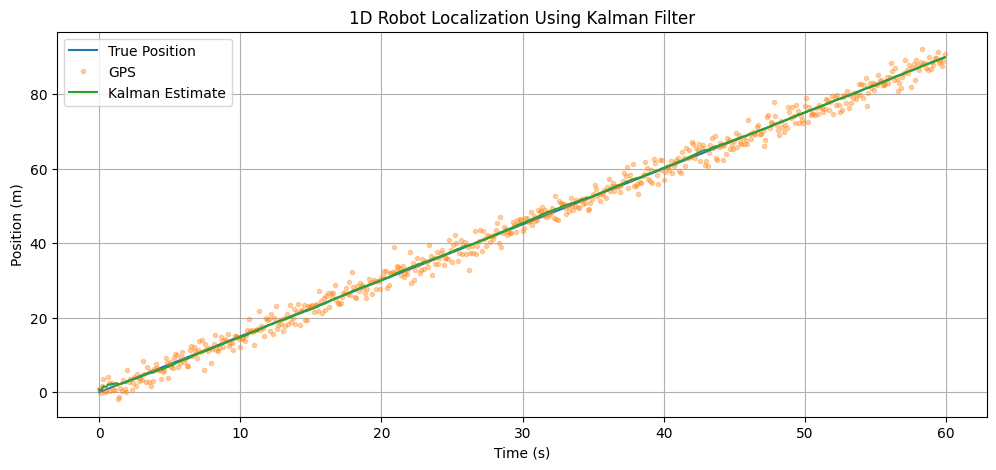

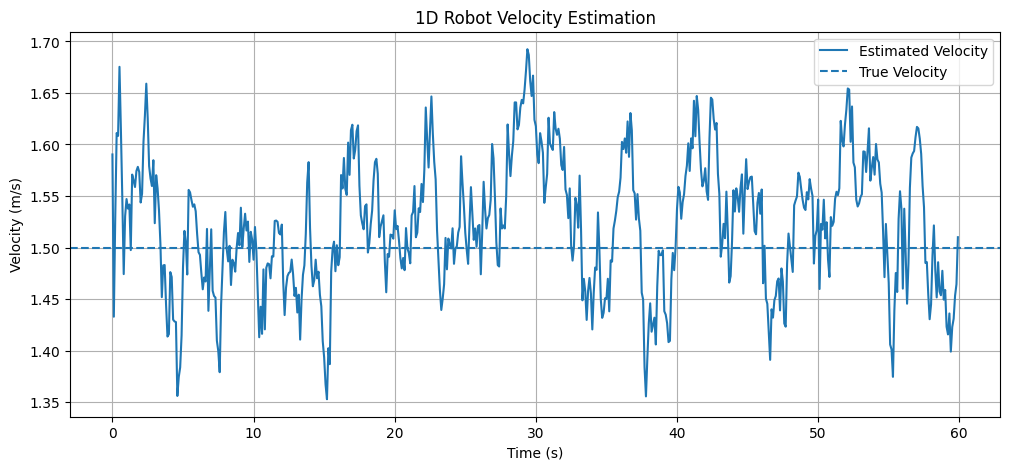

GPS Euclidean Position RMSE: 2.0866 m
Fused Euclidean Position RMSE: 0.2599 m
Fused Velocity RMSE: 0.1039 m/s
Position improvement: 87.55 %


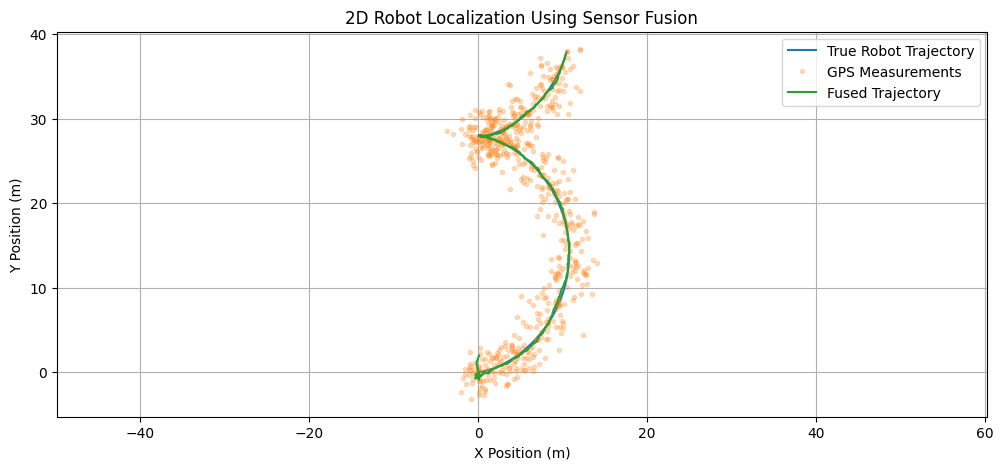

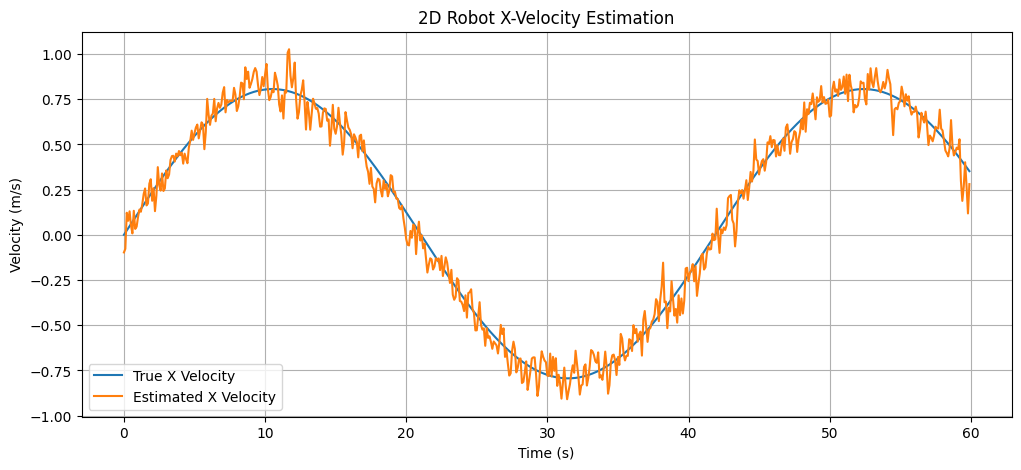

Transformation Round-Trip RMSE: 7.736752145233744e-18 m/s²
Noisy World-Frame IMU RMSE: 0.1514 m/s²


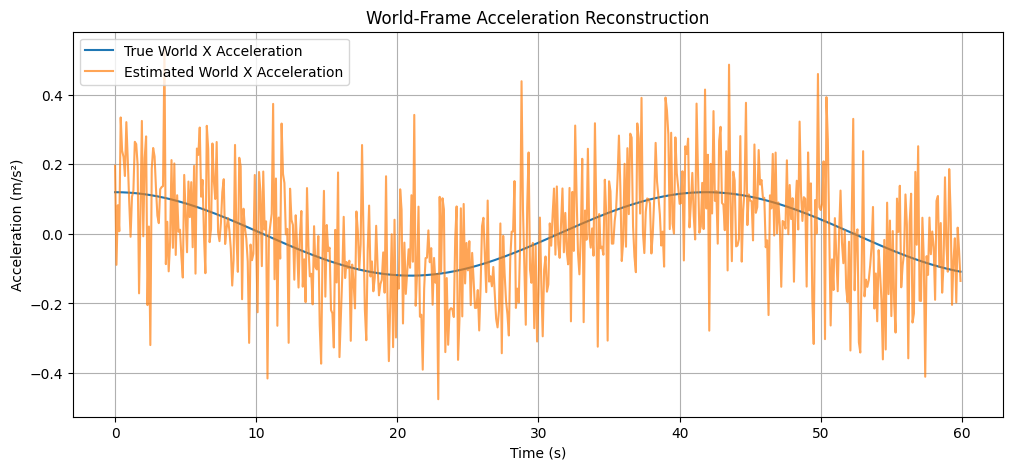

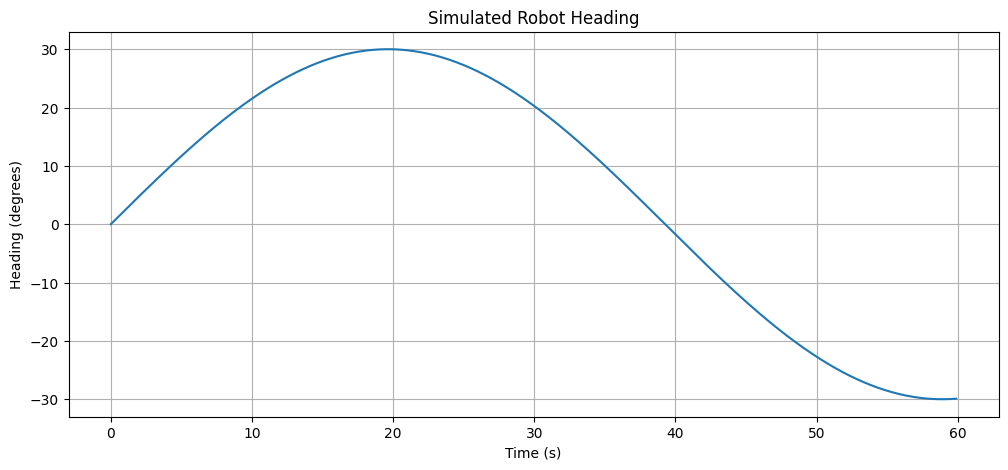

GPS Position RMSE: 2.1283 m
EKF Position RMSE: 0.3325 m
EKF Velocity RMSE: 0.0488 m/s
EKF Heading RMSE: 0.0704 rad
EKF Heading RMSE: 4.04 degrees
Position improvement: 84.37 %


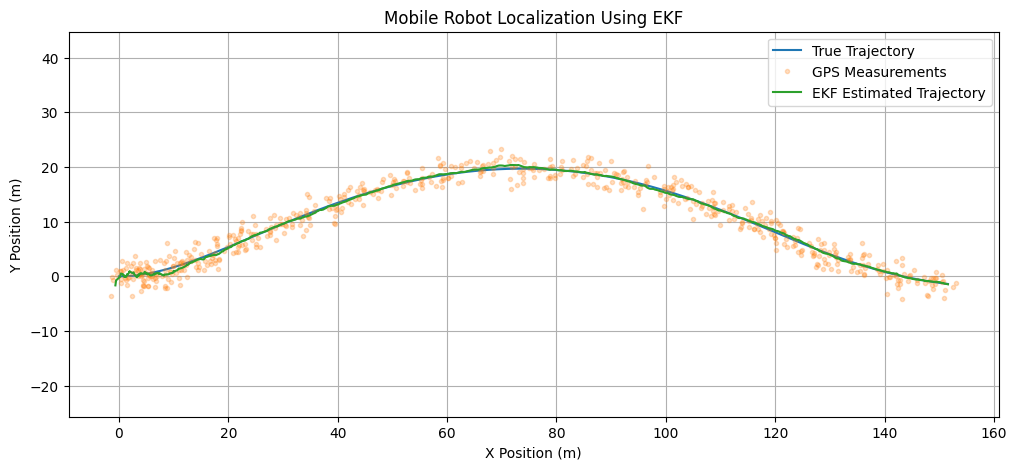

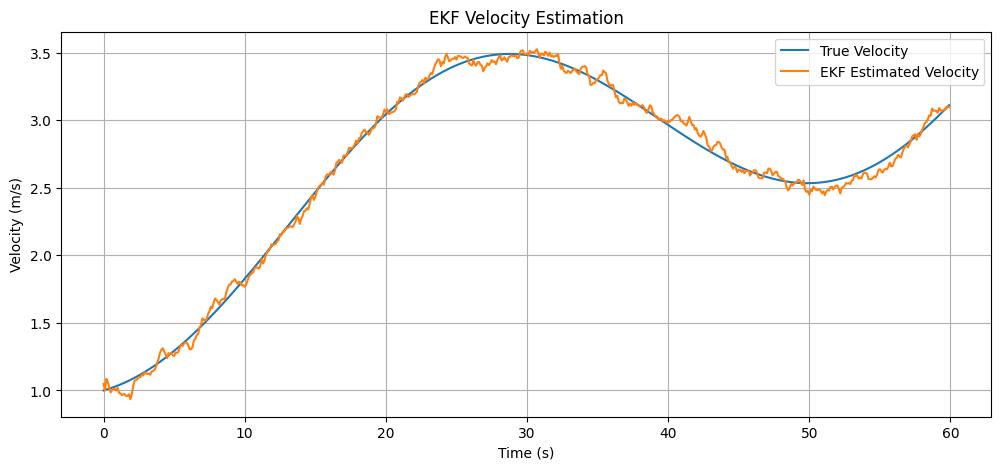

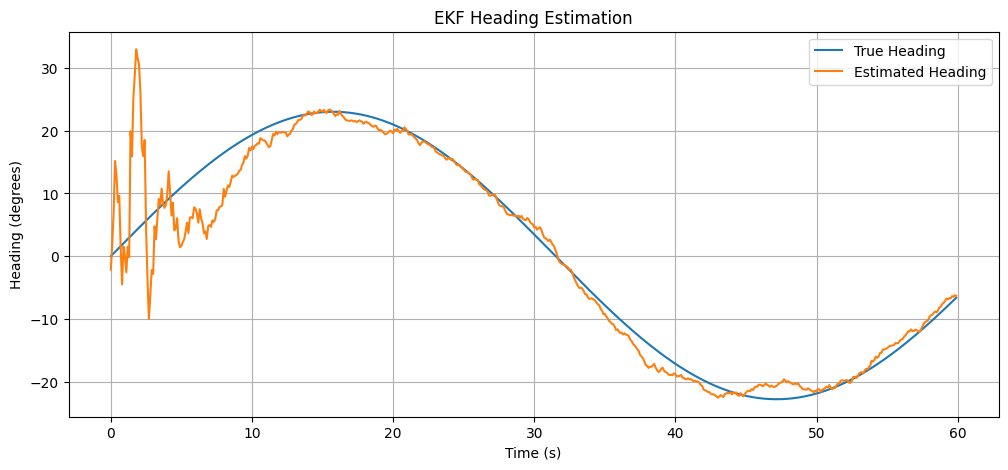

GPS NOISE SENSITIVITY ANALYSIS
-----------------------------------------------------------------
GPS Noise: 0.5 m | GPS RMSE: 0.7094 m | EKF RMSE: 0.1583 m | Improvement: 77.68%
GPS Noise: 1.5 m | GPS RMSE: 2.1283 m | EKF RMSE: 0.3325 m | Improvement: 84.37%
GPS Noise: 3.0 m | GPS RMSE: 4.2565 m | EKF RMSE: 0.5425 m | Improvement: 87.26%


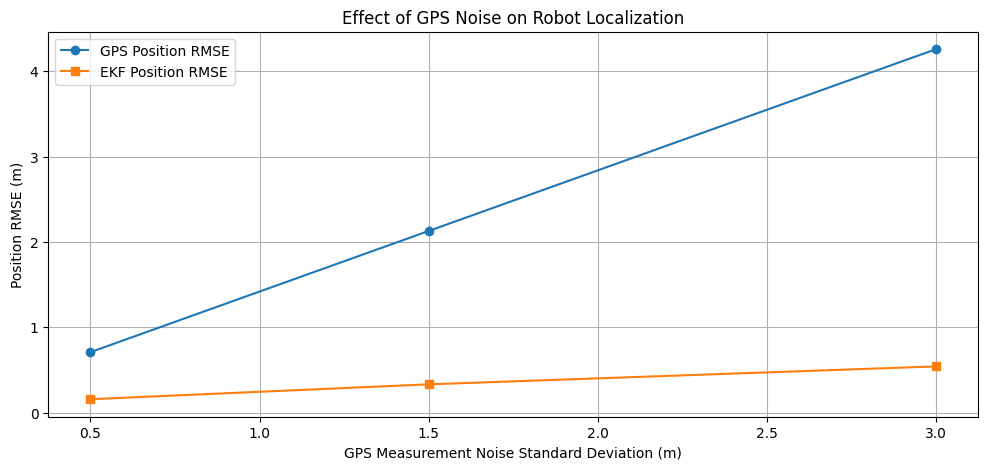

GYROSCOPE NOISE SENSITIVITY ANALYSIS
-----------------------------------------------------------------
Gyro Noise: 0.005 rad/s | Position RMSE: 0.2932 m | Heading RMSE: 0.0635 rad | Heading Error: 3.64 degrees
Gyro Noise: 0.03 rad/s | Position RMSE: 0.3325 m | Heading RMSE: 0.0704 rad | Heading Error: 4.04 degrees
Gyro Noise: 0.08 rad/s | Position RMSE: 0.4071 m | Heading RMSE: 0.0886 rad | Heading Error: 5.07 degrees


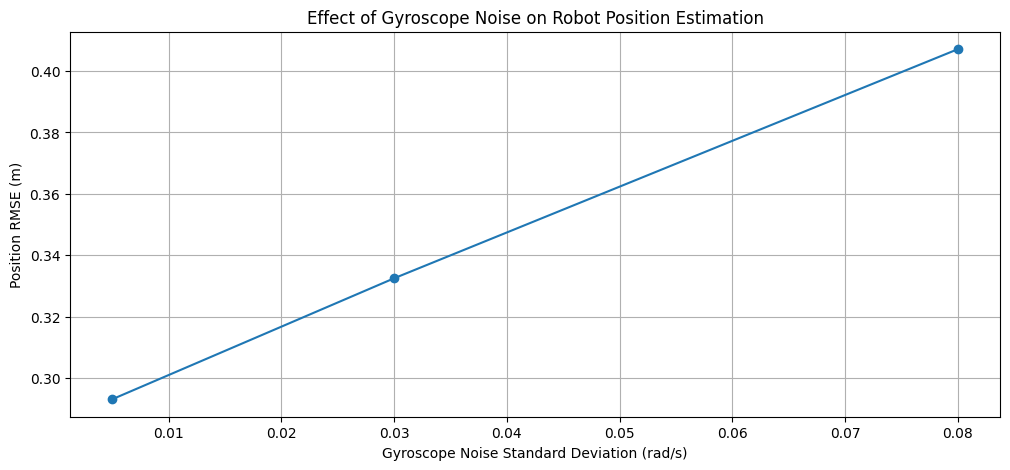

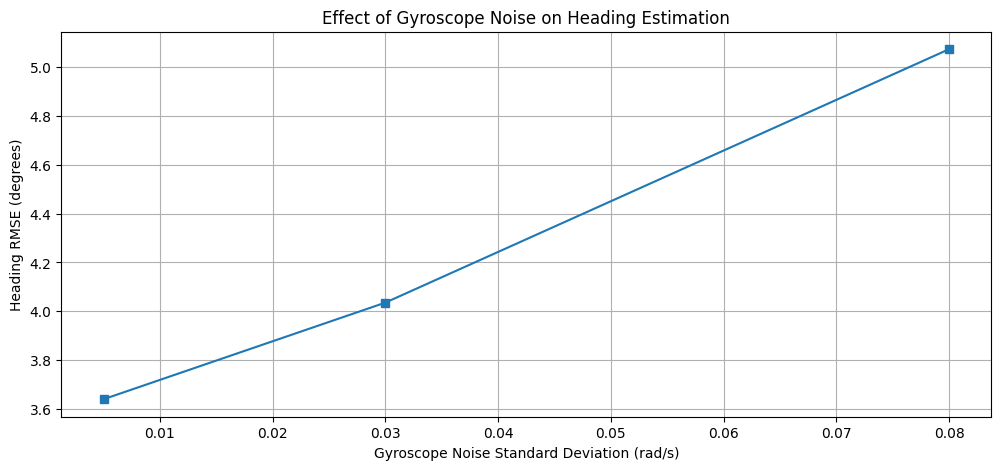

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# Reproducibility
np.random.seed(42)

# Plot settings
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True

print("Libraries imported successfully.")
print("Project: Multi-Sensor Data Fusion and Robot Position Estimation")

#STAGE1 one dimension kalman filter
# Simulation parameters
dt = 0.1
simulation_time = 60
time = np.arange(0, simulation_time, dt)
n = len(time)

true_velocity = 1.5
true_position = true_velocity * time

# Simulated sensor measurements
gps_noise_std = 2.0
encoder_noise_std = 0.25

gps_measurements = (
    true_position +
    np.random.normal(0, gps_noise_std, n)
)

encoder_measurements = (
    true_velocity +
    np.random.normal(0, encoder_noise_std, n)
)

# Kalman Filter state: [position, velocity]
x = np.array([[0.0], [0.0]])

P = np.diag([10.0, 1.0])

F = np.array([
    [1, dt],
    [0, 1]
])

H = np.eye(2)

Q = np.diag([0.001, 0.001])

R = np.diag([
    gps_noise_std**2,
    encoder_noise_std**2
])

estimated_position = []
estimated_velocity = []

for k in range(n):

    # Prediction
    x = F @ x
    P = F @ P @ F.T + Q

    # Measurement update
    z = np.array([
        [gps_measurements[k]],
        [encoder_measurements[k]]
    ])

    y = z - H @ x
    S = H @ P @ H.T + R
    K = P @ H.T @ np.linalg.inv(S)

    x = x + K @ y
    P = (np.eye(2) - K @ H) @ P

    estimated_position.append(x[0, 0])
    estimated_velocity.append(x[1, 0])

estimated_position = np.array(estimated_position)
estimated_velocity = np.array(estimated_velocity)

# Performance evaluation
gps_rmse = np.sqrt(np.mean(
    (gps_measurements - true_position)**2
))

fused_rmse = np.sqrt(np.mean(
    (estimated_position - true_position)**2
))

velocity_rmse = np.sqrt(np.mean(
    (estimated_velocity - true_velocity)**2
))

print("GPS Position RMSE:", round(gps_rmse, 4), "m")
print("Fused Position RMSE:", round(fused_rmse, 4), "m")
print("Fused Velocity RMSE:", round(velocity_rmse, 4), "m/s")

improvement = (1 - fused_rmse / gps_rmse) * 100
print("Position accuracy improvement:", round(improvement, 2), "%")

# Plot
plt.figure()
plt.plot(time, true_position, label="True Position")
plt.plot(time, gps_measurements, ".", alpha=0.35, label="GPS")
plt.plot(time, estimated_position, label="Kalman Estimate")
plt.xlabel("Time (s)")
plt.ylabel("Position (m)")
plt.title("1D Robot Localization Using Kalman Filter")
plt.legend()
plt.show()

plt.figure()
plt.plot(time, estimated_velocity, label="Estimated Velocity")
plt.axhline(true_velocity, linestyle="--", label="True Velocity")
plt.xlabel("Time (s)")
plt.ylabel("Velocity (m/s)")
plt.title("1D Robot Velocity Estimation")
plt.legend()
plt.show()

#STAGE 2: Two dimensional sensor fusion

# Simulation parameters
dt = 0.1
simulation_time = 60
time = np.arange(0, simulation_time, dt)
n = len(time)

# True acceleration profile
true_ax = 0.12 * np.cos(0.15 * time)
true_ay = 0.10 * np.sin(0.15 * time)

# True velocity and position
true_vx = np.zeros(n)
true_vy = np.zeros(n)
true_x = np.zeros(n)
true_y = np.zeros(n)

for k in range(1, n):
    true_vx[k] = true_vx[k-1] + true_ax[k-1] * dt
    true_vy[k] = true_vy[k-1] + true_ay[k-1] * dt

    true_x[k] = true_x[k-1] + true_vx[k-1] * dt
    true_y[k] = true_y[k-1] + true_vy[k-1] * dt

# Sensor noise
gps_noise_std = 1.5
imu_noise_std = 0.15
wheel_noise_std = 0.12

gps_x = true_x + np.random.normal(0, gps_noise_std, n)
gps_y = true_y + np.random.normal(0, gps_noise_std, n)

imu_ax = true_ax + np.random.normal(0, imu_noise_std, n)
imu_ay = true_ay + np.random.normal(0, imu_noise_std, n)

wheel_vx = true_vx + np.random.normal(0, wheel_noise_std, n)
wheel_vy = true_vy + np.random.normal(0, wheel_noise_std, n)

# State: [x, y, vx, vy]
state = np.zeros((4, 1))
P = np.diag([5.0, 5.0, 1.0, 1.0])

F = np.array([
    [1, 0, dt, 0],
    [0, 1, 0, dt],
    [0, 0, 1, 0],
    [0, 0, 0, 1]
])

B = np.array([
    [0.5 * dt**2, 0],
    [0, 0.5 * dt**2],
    [dt, 0],
    [0, dt]
])

H = np.eye(4)

Q = np.diag([0.001, 0.001, 0.01, 0.01])

R = np.diag([
    gps_noise_std**2,
    gps_noise_std**2,
    wheel_noise_std**2,
    wheel_noise_std**2
])

fused_states = []

for k in range(n):

    acceleration = np.array([
        [imu_ax[k]],
        [imu_ay[k]]
    ])

    # Prediction
    state = F @ state + B @ acceleration
    P = F @ P @ F.T + Q

    # GPS and wheel odometry update
    measurement = np.array([
        [gps_x[k]],
        [gps_y[k]],
        [wheel_vx[k]],
        [wheel_vy[k]]
    ])

    innovation = measurement - H @ state
    S = H @ P @ H.T + R
    K = P @ H.T @ np.linalg.inv(S)

    state = state + K @ innovation
    P = (np.eye(4) - K @ H) @ P

    fused_states.append(state.flatten())

fused_states = np.array(fused_states)

fused_x = fused_states[:, 0]
fused_y = fused_states[:, 1]
fused_vx = fused_states[:, 2]
fused_vy = fused_states[:, 3]

# Position and velocity evaluation
gps_position_rmse = np.sqrt(np.mean(
    (gps_x - true_x)**2 + (gps_y - true_y)**2
))

fused_position_rmse = np.sqrt(np.mean(
    (fused_x - true_x)**2 + (fused_y - true_y)**2
))

fused_velocity_rmse = np.sqrt(np.mean(
    (fused_vx - true_vx)**2 + (fused_vy - true_vy)**2
))

print("GPS Euclidean Position RMSE:",
      round(gps_position_rmse, 4), "m")

print("Fused Euclidean Position RMSE:",
      round(fused_position_rmse, 4), "m")

print("Fused Velocity RMSE:",
      round(fused_velocity_rmse, 4), "m/s")

print("Position improvement:",
      round((1 - fused_position_rmse/gps_position_rmse)*100, 2),
      "%")

# Trajectory plot
plt.figure()
plt.plot(true_x, true_y, label="True Robot Trajectory")
plt.plot(gps_x, gps_y, ".", alpha=0.25, label="GPS Measurements")
plt.plot(fused_x, fused_y, label="Fused Trajectory")
plt.xlabel("X Position (m)")
plt.ylabel("Y Position (m)")
plt.title("2D Robot Localization Using Sensor Fusion")
plt.legend()
plt.axis("equal")
plt.show()

# Velocity plot
plt.figure()
plt.plot(time, true_vx, label="True X Velocity")
plt.plot(time, fused_vx, label="Estimated X Velocity")
plt.xlabel("Time (s)")
plt.ylabel("Velocity (m/s)")
plt.title("2D Robot X-Velocity Estimation")
plt.legend()
plt.show()

#STAGE 3: Coordinate Transfirmation

# Simulation parameters
dt = 0.1
simulation_time = 60
time = np.arange(0, simulation_time, dt)
n = len(time)

# Robot heading changes with time
yaw = np.deg2rad(30 * np.sin(0.08 * time))

# True acceleration in world coordinates
true_acceleration_world = np.column_stack((
    0.12 * np.cos(0.15 * time),
    0.10 * np.sin(0.15 * time)
))

# Convert world-frame acceleration to body-frame acceleration
acceleration_body = np.zeros((n, 2))

for k in range(n):
    c = np.cos(yaw[k])
    s = np.sin(yaw[k])

    R = np.array([
        [c, -s],
        [s,  c]
    ])

    acceleration_body[k] = R.T @ true_acceleration_world[k]

# Add sensor noise in the body frame
body_noise_std = 0.15

measured_acceleration_body = (
    acceleration_body +
    np.random.normal(0, body_noise_std, (n, 2))
)

# Transform measured acceleration back into world coordinates
estimated_acceleration_world = np.zeros((n, 2))

for k in range(n):
    c = np.cos(yaw[k])
    s = np.sin(yaw[k])

    R = np.array([
        [c, -s],
        [s,  c]
    ])

    estimated_acceleration_world[k] = (
        R @ measured_acceleration_body[k]
    )

# Compare exact transformation round-trip without noise
round_trip_world = np.zeros((n, 2))

for k in range(n):
    c = np.cos(yaw[k])
    s = np.sin(yaw[k])

    R = np.array([
        [c, -s],
        [s,  c]
    ])

    round_trip_world[k] = R @ acceleration_body[k]

transformation_rmse = np.sqrt(np.mean(
    (round_trip_world - true_acceleration_world)**2
))

imu_rmse = np.sqrt(np.mean(
    (estimated_acceleration_world - true_acceleration_world)**2
))

print("Transformation Round-Trip RMSE:",
      transformation_rmse, "m/s²")

print("Noisy World-Frame IMU RMSE:",
      round(imu_rmse, 4), "m/s²")

# Plot acceleration comparison
plt.figure()

plt.plot(
    time,
    true_acceleration_world[:, 0],
    label="True World X Acceleration"
)

plt.plot(
    time,
    estimated_acceleration_world[:, 0],
    alpha=0.7,
    label="Estimated World X Acceleration"
)

plt.xlabel("Time (s)")
plt.ylabel("Acceleration (m/s²)")
plt.title("World-Frame Acceleration Reconstruction")
plt.legend()
plt.show()

# Plot heading
plt.figure()
plt.plot(time, np.rad2deg(yaw))
plt.xlabel("Time (s)")
plt.ylabel("Heading (degrees)")
plt.title("Simulated Robot Heading")
plt.show()

#STAGE 4: Extended Kalman filter

def run_ekf(gps_std=1.5, gyro_std=0.03,
            acceleration_std=0.15,
            wheel_std=0.12, seed=123):

    rng = np.random.default_rng(seed)

    dt = 0.1
    simulation_time = 60
    time = np.arange(0, simulation_time, dt)
    n = len(time)

    # True robot motion
    true_x = np.zeros(n)
    true_y = np.zeros(n)
    true_v = np.zeros(n)
    true_theta = np.zeros(n)

    true_v[0] = 1.0
    true_theta[0] = 0.0

    true_acceleration = 0.10 * np.sin(0.12 * time) + 0.03
    true_gyro = 0.04 * np.cos(0.10 * time)

    for k in range(1, n):
        true_x[k] = (
            true_x[k-1] +
            true_v[k-1] * np.cos(true_theta[k-1]) * dt
        )

        true_y[k] = (
            true_y[k-1] +
            true_v[k-1] * np.sin(true_theta[k-1]) * dt
        )

        true_v[k] = (
            true_v[k-1] +
            true_acceleration[k-1] * dt
        )

        true_theta[k] = (
            true_theta[k-1] +
            true_gyro[k-1] * dt
        )

    # Simulated sensor measurements
    gps_x = true_x + rng.normal(0, gps_std, n)
    gps_y = true_y + rng.normal(0, gps_std, n)

    wheel_speed = (
        true_v + rng.normal(0, wheel_std, n)
    )

    measured_acceleration = (
        true_acceleration +
        rng.normal(0, acceleration_std, n)
    )

    measured_gyro = (
        true_gyro + rng.normal(0, gyro_std, n)
    )

    # Initial EKF state
    state = np.array([
        [0.0],
        [0.0],
        [1.0],
        [0.0]
    ])

    P = np.diag([2.0, 2.0, 0.5, 0.5])

    # Measurement covariance: GPS x, GPS y, wheel speed
    R_meas = np.diag([
        gps_std**2,
        gps_std**2,
        wheel_std**2
    ])

    # Small baseline process covariance
    Q_base = np.diag([
        1e-6, 1e-6, 1e-6, 1e-6
    ])

    estimated_states = []

    for k in range(n):

        v = state[2, 0]
        theta = state[3, 0]

        a = measured_acceleration[k]
        omega = measured_gyro[k]

        # Nonlinear motion prediction
        state[0, 0] += v * np.cos(theta) * dt
        state[1, 0] += v * np.sin(theta) * dt
        state[2, 0] += a * dt
        state[3, 0] += omega * dt

        # Jacobian of the motion model
        F = np.array([
            [1, 0, np.cos(theta)*dt,
             -v*np.sin(theta)*dt],

            [0, 1, np.sin(theta)*dt,
             v*np.cos(theta)*dt],

            [0, 0, 1, 0],

            [0, 0, 0, 1]
        ])

        # Process noise propagation for acceleration and gyro
        G = np.array([
            [0, 0],
            [0, 0],
            [dt, 0],
            [0, dt]
        ])

        M = np.diag([
            acceleration_std**2,
            gyro_std**2
        ])

        Q = Q_base + G @ M @ G.T

        P = F @ P @ F.T + Q

        # GPS and wheel speed measurements
        z = np.array([
            [gps_x[k]],
            [gps_y[k]],
            [wheel_speed[k]]
        ])

        H = np.array([
            [1, 0, 0, 0],
            [0, 1, 0, 0],
            [0, 0, 1, 0]
        ])

        # EKF measurement correction
        innovation = z - H @ state

        S = H @ P @ H.T + R_meas
        K = np.linalg.solve(S, H @ P).T

        state = state + K @ innovation

        # Joseph covariance update
        I = np.eye(4)
        P = (
            (I - K @ H) @ P @ (I - K @ H).T
            + K @ R_meas @ K.T
        )

        estimated_states.append(state.flatten())

    estimated_states = np.array(estimated_states)

    estimated_x = estimated_states[:, 0]
    estimated_y = estimated_states[:, 1]
    estimated_v = estimated_states[:, 2]
    estimated_theta = estimated_states[:, 3]

    # Calculate errors
    gps_rmse = np.sqrt(np.mean(
        (gps_x - true_x)**2 + (gps_y - true_y)**2
    ))

    ekf_rmse = np.sqrt(np.mean(
        (estimated_x - true_x)**2 +
        (estimated_y - true_y)**2
    ))

    velocity_rmse = np.sqrt(np.mean(
        (estimated_v - true_v)**2
    ))

    # Wrapped angular error
    heading_error = (
        estimated_theta - true_theta + np.pi
    ) % (2 * np.pi) - np.pi

    heading_rmse = np.sqrt(np.mean(heading_error**2))

    improvement = (
        1 - ekf_rmse / gps_rmse
    ) * 100

    return {
        "time": time,
        "true_x": true_x,
        "true_y": true_y,
        "gps_x": gps_x,
        "gps_y": gps_y,
        "estimated_x": estimated_x,
        "estimated_y": estimated_y,
        "true_v": true_v,
        "estimated_v": estimated_v,
        "true_theta": true_theta,
        "estimated_theta": estimated_theta,
        "gps_rmse": gps_rmse,
        "ekf_rmse": ekf_rmse,
        "velocity_rmse": velocity_rmse,
        "heading_rmse": heading_rmse,
        "improvement": improvement
    }


# Run the EKF simulation
ekf_results = run_ekf()

print("GPS Position RMSE:",
      round(ekf_results["gps_rmse"], 4), "m")

print("EKF Position RMSE:",
      round(ekf_results["ekf_rmse"], 4), "m")

print("EKF Velocity RMSE:",
      round(ekf_results["velocity_rmse"], 4), "m/s")

print("EKF Heading RMSE:",
      round(ekf_results["heading_rmse"], 4), "rad")

print("EKF Heading RMSE:",
      round(np.rad2deg(ekf_results["heading_rmse"]), 2),
      "degrees")

print("Position improvement:",
      round(ekf_results["improvement"], 2), "%")

# Plot robot trajectory
plt.figure()

plt.plot(
    ekf_results["true_x"],
    ekf_results["true_y"],
    label="True Trajectory"
)

plt.plot(
    ekf_results["gps_x"],
    ekf_results["gps_y"],
    ".",
    alpha=0.25,
    label="GPS Measurements"
)

plt.plot(
    ekf_results["estimated_x"],
    ekf_results["estimated_y"],
    label="EKF Estimated Trajectory"
)

plt.xlabel("X Position (m)")
plt.ylabel("Y Position (m)")
plt.title("Mobile Robot Localization Using EKF")
plt.legend()
plt.axis("equal")
plt.show()

# Plot velocity
plt.figure()

plt.plot(
    ekf_results["time"],
    ekf_results["true_v"],
    label="True Velocity"
)

plt.plot(
    ekf_results["time"],
    ekf_results["estimated_v"],
    label="EKF Estimated Velocity"
)

plt.xlabel("Time (s)")
plt.ylabel("Velocity (m/s)")
plt.title("EKF Velocity Estimation")
plt.legend()
plt.show()

# Plot heading
plt.figure()

plt.plot(
    ekf_results["time"],
    np.rad2deg(ekf_results["true_theta"]),
    label="True Heading"
)

plt.plot(
    ekf_results["time"],
    np.rad2deg(ekf_results["estimated_theta"]),
    label="Estimated Heading"
)

plt.xlabel("Time (s)")
plt.ylabel("Heading (degrees)")
plt.title("EKF Heading Estimation")
plt.legend()
plt.show()

#STAGE 5A: GPS Noise Experiment

gps_noise_levels = [0.5, 1.5, 3.0]

gps_experiment_results = []

for noise in gps_noise_levels:

    result = run_ekf(
        gps_std=noise,
        gyro_std=0.03,
        seed=123
    )

    gps_experiment_results.append({
        "GPS Noise": noise,
        "GPS RMSE": result["gps_rmse"],
        "EKF RMSE": result["ekf_rmse"],
        "Improvement (%)": result["improvement"]
    })

print("GPS NOISE SENSITIVITY ANALYSIS")
print("-" * 65)

for result in gps_experiment_results:
    print(
        f"GPS Noise: {result['GPS Noise']} m | "
        f"GPS RMSE: {result['GPS RMSE']:.4f} m | "
        f"EKF RMSE: {result['EKF RMSE']:.4f} m | "
        f"Improvement: {result['Improvement (%)']:.2f}%"
    )

# Plot results
plt.figure()

plt.plot(
    [r["GPS Noise"] for r in gps_experiment_results],
    [r["GPS RMSE"] for r in gps_experiment_results],
    marker="o",
    label="GPS Position RMSE"
)

plt.plot(
    [r["GPS Noise"] for r in gps_experiment_results],
    [r["EKF RMSE"] for r in gps_experiment_results],
    marker="s",
    label="EKF Position RMSE"
)

plt.xlabel("GPS Measurement Noise Standard Deviation (m)")
plt.ylabel("Position RMSE (m)")
plt.title("Effect of GPS Noise on Robot Localization")
plt.legend()
plt.show()

#STAGE 5B: Gyroscope noise Experiment

gyro_noise_levels = [0.005, 0.03, 0.08]

gyro_experiment_results = []

for noise in gyro_noise_levels:

    result = run_ekf(
        gps_std=1.5,
        gyro_std=noise,
        seed=123
    )

    gyro_experiment_results.append({
        "Gyro Noise": noise,
        "Position RMSE": result["ekf_rmse"],
        "Heading RMSE": result["heading_rmse"],
        "Heading Error (degrees)": np.rad2deg(
            result["heading_rmse"]
        )
    })

print("GYROSCOPE NOISE SENSITIVITY ANALYSIS")
print("-" * 65)

for result in gyro_experiment_results:
    print(
        f"Gyro Noise: {result['Gyro Noise']} rad/s | "
        f"Position RMSE: {result['Position RMSE']:.4f} m | "
        f"Heading RMSE: {result['Heading RMSE']:.4f} rad | "
        f"Heading Error: {result['Heading Error (degrees)']:.2f} degrees"
    )

# Plot position sensitivity
plt.figure()

plt.plot(
    [r["Gyro Noise"] for r in gyro_experiment_results],
    [r["Position RMSE"] for r in gyro_experiment_results],
    marker="o"
)

plt.xlabel("Gyroscope Noise Standard Deviation (rad/s)")
plt.ylabel("Position RMSE (m)")
plt.title("Effect of Gyroscope Noise on Robot Position Estimation")
plt.show()

# Plot heading sensitivity
plt.figure()

plt.plot(
    [r["Gyro Noise"] for r in gyro_experiment_results],
    [r["Heading Error (degrees)"] for r in gyro_experiment_results],
    marker="s"
)

plt.xlabel("Gyroscope Noise Standard Deviation (rad/s)")
plt.ylabel("Heading RMSE (degrees)")
plt.title("Effect of Gyroscope Noise on Heading Estimation")
plt.show()

#Project conclusion

#This project investigated multi-sensor data fusion for simulated mobile robot localization using Python. Five major stages were explored, beginning with a one-dimensional Kalman Filter and progressing to two-dimensional sensor fusion, coordinate transformations, Extended Kalman Filtering and sensor noise sensitivity analysis.

#The simulations demonstrated how GPS, wheel odometry, accelerometer and gyroscope measurements can be integrated to estimate robot position, velocity and heading.

#The project strengthened my understanding of state estimation, sensor uncertainty, coordinate transformations and nonlinear motion modelling. It also provides a foundation for further research into ROS 2, robot simulation, sensor integration and multi-robot manufacturing systems.